# Notebook 1: Data Exploration

Welcome!, The main goal for this notebook is to provide a deep understanding of the dataset, its characteristics, and any hidden patterns.

---

## Introduction

#### Data Description

This project analyzes radio continuum data from the MeerKAT International GHz Tiered Extragalactic Exploration ([MIGHTEE](https://idia.ac.za/mightee/)) survey, focusing on extragalactic radio emissions in the COSMOS field. MIGHTEE offers insights into galaxy evolution, given its depth and multiwavelength coverage. The COSMOS field, devoid of bright radio, UV, and X-ray sources, is ideal for deep astronomical surveys.

The MIGHTEE data includes deep fields like COSMOS, XMM-LSS, E-CDFS and ELAIS-S1, covering a 20 deg^2 total area at a central frequency of 1284 MHz. These fields were observed using MeerKAT's L-band receivers for about 1000 hours. They were chosen due to their extensive multiwavelength data from prior and potential future surveys.

The Mightee Cosmos Field: cred: [Hale et al.](https://arxiv.org/abs/2411.04958)

![My chart](images/cosmos.jpg)

The **MIGHTEE-COSMOS multiwavelength catalogue** we will use here combines radio data with optical, near-to-far infrared, and X-ray measurements from various sources in the COSMOS field. The main radio catalogue was cross-matched with optical and near-infrared data from other studies, resulting in a matched set of 5,224 radio sources. Additionally, 572 of these sources were detected in X-ray observations. This dataset also incorporated Mid-Infrared (MIR) data, referencing specific IRAC flux densities. The catalogue further integrated far-infrared data from the Herschel Extra-galactic Legacy Project, identifying thousands of radio sources across different instruments.

#### Why Multiwavelength?
- Different wavelengths probe different physical processes and components of astronomical objects.
- For example, radio waves can reveal cold gas and magnetic fields, while X-rays can reveal hot gas and high-energy processes.
- By combining data from multiple wavelengths, astronomers can gain a more comprehensive understanding of the structure, composition, and dynamics of celestial objects and phenomena.

#### Example
Centaurus A in Different Wavelengths (Hubble, Spitzer, Chandra, VLA)

![My chart](images/centaurus_a.png)

Image_cred: https://science.nasa.gov/asset/webb/centaurus-a-in-different-wavelengths-hubble-spitzer-chandra-vla/

#### Why explore the data?

Data exploration serves as the foundational step in data analysis, aimed at understanding inherent structures, patterns, and potential anomalies within a dataset. It helps ascertain the quality of data, understand features' distributions, formulate hypotheses, guide preprocessing decisions, and select appropriate analytical tools and models. Efficient data exploration also aids in communicating initial insights to stakeholders. In this notebook, we will perform some of these critical tasks.

---

### Step 1: Import libraries needed for analysis

In [159]:
import numpy as np 
import matplotlib.pyplot as plt 
import pandas as pd 
import astropy.io.fits as fits 


---

### Step 2: Read data

In [160]:
hdul = fits.open("data/updated_mightee_cat.fits")
mightee_data = pd.DataFrame(hdul[1].data)
hdul.close()

In [161]:
mightee_data.shape

(5223, 154)

From above we can observe that we have 167 columns (which will be referred to as feateres) and 5223 rows. We can run the following command to see what are those feature names:

In [162]:
list(mightee_data.columns)
# list(mightee_data.columns[:10]) # printing the first 10 columns
# These columns/ Features described in the following file @@ data/README_MIGHTEE.pdf. Please refer to the file for more details about the features.

['CATID',
 'GAUS_ID_NEW',
 'RADIORA',
 'RADIODEC',
 'TOTALFLUX',
 'TOTALFLUXERR',
 'PEAKFLUX',
 'PEAKFLUXERR',
 'MATCHID',
 'NCOMP',
 'OPTICALRA',
 'OPTICALDEC',
 'FLAG',
 'ID_1',
 'X_IMAGE',
 'Y_IMAGE',
 'RA_1',
 'DEC_1',
 'flux_CFHT-u',
 'flux_CFHT-g',
 'flux_CFHT-r',
 'flux_CFHT-iy',
 'flux_CFHT-z',
 'flux_HSC-G',
 'flux_HSC-R',
 'flux_HSC-I',
 'flux_HSC-NB0816',
 'flux_HSC-Z',
 'flux_SC-z',
 'flux_HSC-NB0921',
 'flux_HSC-Y',
 'flux_Y',
 'flux_J',
 'flux_H',
 'flux_Ks',
 'flux_ch1',
 'flux_ch2',
 'err_CFHT-u',
 'err_CFHT-g',
 'err_CFHT-r',
 'err_CFHT-iy',
 'err_CFHT-z',
 'err_HSC-G',
 'err_HSC-R',
 'err_HSC-I',
 'err_HSC-NB0816',
 'err_HSC-Z',
 'err_SC-z',
 'err_HSC-NB0921',
 'err_HSC-Y',
 'err_Y',
 'err_J',
 'err_H',
 'err_Ks',
 'err_ch1',
 'err_ch2',
 'Separation_1',
 'help_id_1',
 'RA_2_1',
 'Dec_2_1',
 'F_MIPS_24',
 'FErr_MIPS_24_u',
 'FErr_MIPS_24_l',
 'Bkg_MIPS_24',
 'Sig_conf_MIPS_24',
 'Rhat_MIPS_24',
 'n_eff_MIPS_24',
 'Pval_res_24',
 'Separation_1a',
 'HELP_ID_2',
 'RA_1a'

### Step 3: Cleaning missing data

In [163]:
# Now lets check if the dataframe has any missing values. This is important because missing values can affect the performance of machine learning models and may require imputation or removal of rows/columns with missing data.
# The output is True, which means there are missing values in the dataframe. This is not good news as it means we can not proceed with our analysis without worrying about missing data.
# It is also common in astronomy that data will contain negative values for flux such as -99. this is not an actual measurement and also represent missing values so it needs to be treated as missing data. 
# We will replace -99 with NaN (Not a Number) which is the standard way to represent missing values in pandas.

# converting -99 to NaN
mightee_data.replace(-99, np.nan, inplace=True)

# checking for missing values again after replacing -99 with NaN
print(mightee_data.isna().any().any()) 

True


The dataframe appears to contain missing values (And not sure how much so far), so our first step is to clean the data. As a starting point, the code block below removes all columns in the catalogue with more than 10% missing values. While this threshold is commonly used in practice, it is worth considering whether 10% is the most appropriate choice for this dataset. Are there alternative strategies for handling missing data that might preserve more information? We will explore these questions in the next task.


In [164]:
# Check for missing values by column and remove columns with 90% or more missing data
missing_frac = mightee_data.isna().mean()
cols_to_drop = missing_frac[missing_frac >= 0.10].index.tolist()

if cols_to_drop:
    print(f"Deleting {len(cols_to_drop)} columns with >= 10% missing data:")
    for col in cols_to_drop:
        print(" -", col)
    mightee_data = mightee_data.drop(columns=cols_to_drop)
else:
    print("No columns with >= 10% missing data found.")


Deleting 32 columns with >= 10% missing data:
 - RA_2_1
 - Dec_2_1
 - F_MIPS_24
 - FErr_MIPS_24_u
 - FErr_MIPS_24_l
 - Bkg_MIPS_24
 - Sig_conf_MIPS_24
 - Rhat_MIPS_24
 - n_eff_MIPS_24
 - Pval_res_24
 - Separation_1a
 - RA_1a
 - Dec_1a
 - F_PACS_100
 - FErr_PACS_100_u
 - FErr_PACS_100_l
 - F_PACS_160
 - FErr_PACS_160_u
 - FErr_PACS_160_l
 - Bkg_PACS_100
 - Bkg_PACS_160
 - Sig_conf_PACS_100
 - Sig_conf_PACS_160
 - Rhat_PACS_100
 - Rhat_PACS_160
 - n_eff_PACS_100
 - n_eff_PACS_160
 - Pval_res_100
 - Pval_res_160
 - Separation_1b
 - class_star
 - COS_best_z_uncertainty_v5


### Exercise 1 
- remove missing values from the remaining catalogue, ie remove any row that has a missing value.


In [165]:
#### Answer to Exercise 1 here:

mightee_data.dropna(inplace=True) #delete this line

### Exercise 2 
- Uncomment and run the cell block below to remove the object coordinates from the data set and the ID colums

In [166]:
import re

def is_coord_col(name: str) -> bool:
    s = str(name).strip()
    # Match standalone tokens 'ra'/'dec', occurrences separated by non-letters (e.g., 'ra_1a'),
    # or as a suffix (e.g., 'RADIORA'). Avoid matching inside ordinary words like 'radius'.
    pat = re.compile(r'(?i)(?:\b(?:ra|dec)\b|(?:^|[^A-Za-z])(?:ra|dec)(?:[^A-Za-z]|$)|(?:ra|dec)$)')
    return bool(pat.search(s))


def is_id_col(name: str) -> bool:
    s = str(name).strip()
    # Match exact token 'id', token separated by non-alphanumeric characters, or common ID suffixes like MATCHID.
    return bool(re.search(r'(?i)(?:^id$|(?:^|[^A-Za-z0-9])id(?:$|[^A-Za-z0-9])|id$)', s))

coord_cols = [col for col in mightee_data.columns if is_coord_col(col)]
id_cols = [col for col in mightee_data.columns if is_id_col(col)]
print("Coordinate columns found:", coord_cols)
print("ID columns found:", id_cols)

for col in coord_cols:
    cleaned = (
        mightee_data[col]
        .astype(str)
        .str.strip()
        .replace({'': None, 'None': None, 'nan': None})
    )
    mightee_data[col] = pd.to_numeric(cleaned, errors='coerce')

print("Cleaned coordinate columns:", coord_cols)

cols_to_drop = list(dict.fromkeys(coord_cols + id_cols))
mightee_data.drop(columns=cols_to_drop, inplace=True)
print("Dropped columns:", cols_to_drop)

Coordinate columns found: ['RADIORA', 'RADIODEC', 'OPTICALRA', 'OPTICALDEC', 'RA_1', 'DEC_1', 'RA_2a', 'Dec_2a']
ID columns found: ['CATID', 'GAUS_ID_NEW', 'MATCHID', 'ID_1', 'help_id_1', 'HELP_ID_2', 'help_id']
Cleaned coordinate columns: ['RADIORA', 'RADIODEC', 'OPTICALRA', 'OPTICALDEC', 'RA_1', 'DEC_1', 'RA_2a', 'Dec_2a']
Dropped columns: ['RADIORA', 'RADIODEC', 'OPTICALRA', 'OPTICALDEC', 'RA_1', 'DEC_1', 'RA_2a', 'Dec_2a', 'CATID', 'GAUS_ID_NEW', 'MATCHID', 'ID_1', 'help_id_1', 'HELP_ID_2', 'help_id']


In [167]:
#### Explain why we need to clean the coordinate columns and how we cleaned them here:

In [168]:
### After some data cleaning lets see how many rows and columns we have left in the dataframe. 
print("Dataframe shape after cleaning:", mightee_data.shape)

Dataframe shape after cleaning: (4494, 107)


### Step 4: Seperate the features used as input (X) from target (y)

In [169]:
# Firstly, Since the MIGHTEE dataset contains multiple columns that indicate whether a source is an AGN, SFG, unclassified, or a probable SFG,
# we need to consolidate these into a single 'labels' column for our task. The function `create_label_column` will take care of this by applying the following logic:
# All you need to do is to run this cell

def create_label_column(df, y_features):
    """Takes a processed MIGHTEE DataFrame, creates a single 'labels'

    column (AGN or SFG), and drops the original four classification columns.

    Parameters:
    -----------
    df : pd.DataFrame
        The DataFrame containing the X features and the 4 target features.
    y_features : list
        A list of exactly 4 strings corresponding to:
        [AGN_col, SFG_col, probSFG_col, unclass_col]

    Returns:
    --------
    pd.DataFrame
        Cleaned DataFrame with a 'labels' column, minus unclassified and
    unnecessary target columns.
    """
    # 1. Create a shallow copy to prevent SettingWithCopyWarning
    processed_df = df.copy()

    # 2. Extract column names for clarity
    agn_col, sfg_col, probsfg_col, unclass_col = y_features

    # 3. Define the conditions and corresponding choices
    conditions = [
        processed_df[agn_col] == True,
        (processed_df[sfg_col] == True) | (processed_df[probsfg_col] == True),
    ]
    choices = ["AGN", "SFG"]

    # FIX: Changed default=np.nan to default='None' so all data types are strings
    processed_df["labels"] = np.select(conditions, choices, default="None")

    # 4. Print shapes before dropping
    print(
        "Shape of AGN: ", processed_df[processed_df["labels"] == "AGN"].shape
    )
    print(
        "Shape of SFG: ", processed_df[processed_df["labels"] == "SFG"].shape
    )
    print(
        "Shape of Unclassified/Dropped: ",
        processed_df[processed_df[unclass_col] == True].shape,
    )

    # 5. Drop rows that are marked as 'None' (the unclassified ones)
    processed_df = processed_df[processed_df["labels"] != "None"]

    # 6. Drop the original 4 target columns
    processed_df = processed_df.drop(columns=y_features)

    # 7. Clean up infinity values
    processed_df = processed_df.replace(-np.inf, np.nan)

    print("DONE PROCESSING")
    return processed_df

mightee_data = create_label_column(
    mightee_data,
    ["AGN", "SFG", "probSFG", "unclass"],
)

Shape of AGN:  (1499, 108)
Shape of SFG:  (2622, 108)
Shape of Unclassified/Dropped:  (373, 108)
DONE PROCESSING


In [170]:
# 1. Separate your target label from the features
X = mightee_data.drop(columns=["labels"])
y = mightee_data["labels"]

### Step 5 Data Types

#### Now lets check the data types
- The next step is to check the data types of the columns in the dataframe. 
- This is important because we want to make sure that all columns are numeric type (float) and not strings or bool. 
- If there are any `object type`, we will need to convert them to numeric type before we can use them for any analysis.

In [171]:
print("Data types of columns:")
print(X.dtypes)
print("-" * 30)

# Check if ANY column contains object (string) or string data types
has_strings = any(
    pd.api.types.is_object_dtype(dtype)
    or pd.api.types.is_string_dtype(dtype)
    for dtype in X.dtypes
)

# 1. Identify which columns contain string/object data types
string_cols = X.select_dtypes(include=["object", "string"]).columns.tolist()

if string_cols:
    print(f"⚠️ Found string data in the following columns: {string_cols}")
    print("Dropping these columns to prepare for scaling...")

    # 2. Drop the string columns from X
    X_numeric = X.drop(columns=string_cols)
else:
    print("✅ No string columns found.")
    X_numeric = X.copy()

# 3. Check for any remaining missing values (NaNs) that might cause scaler to crash
if X_numeric.isna().any().any():
    print(
        "⚠️ Found some missing values (NaNs). Dropping rows with NaNs..."
    )  # scale can't take NaNs either
    X_numeric = X_numeric.dropna()

print("-" * 30)
print(
    f"🚀 Continuing with {X_numeric.shape[1]} purely numeric columns. Proceeding to scale..."
)

Data types of columns:
TOTALFLUX       float64
TOTALFLUXERR    float64
PEAKFLUX        float64
PEAKFLUXERR     float64
NCOMP             int16
                 ...   
fAGN            float64
L14max          float64
L14min          float64
qir             float64
LIR_WHz         float64
Length: 103, dtype: object
------------------------------
⚠️ Found string data in the following columns: ['COS_best_z_note_v5']
Dropping these columns to prepare for scaling...
------------------------------
🚀 Continuing with 102 purely numeric columns. Proceeding to scale...


---

### Step 6: Descriptive Statistics:

**Descriptive statistics** provide a concise overview of the central tendencies, spread, and shape of the data distribution. By observing the mean, median, mode, and standard deviation, we can quickly grasp the characteristics of our dataset and identify potential anomalies or patterns.

In [172]:
desc_stats = X_numeric.describe()

# Display the statistics
desc_stats

,TOTALFLUX,TOTALFLUXERR,PEAKFLUX,PEAKFLUXERR,NCOMP,FLAG,X_IMAGE,Y_IMAGE,flux_CFHT-u,flux_CFHT-g,...,SFR_opt_hi_AGNfitter,ef,S14,L14,fSF,fAGN,L14max,L14min,qir,LIR_WHz
count,4121.000000,4121.000000,4121.000000,4121.000000,4121.000000,4121.000000,4121.000000,4121.000000,4.121000e+03,4.121000e+03,...,4.121000e+03,4.121000e+03,4121.000000,4.121000e+03,4121.000000,4121.000000,4.121000e+03,4.121000e+03,4121.000000,4.121000e+03
mean,0.000196,0.000059,0.000134,0.000005,1.045135,100.885222,16165.755859,15050.661133,1.595324e-29,3.566601e-29,...,1.109475e+03,1.361398e+09,0.000192,1.146263e+24,0.611830,0.427122,1.702933e+24,4.089675e+23,2.033668,6.504920e+25
std,0.002026,0.001995,0.000750,0.000001,0.856954,3.455217,5898.581055,5807.981934,4.301468e-29,9.585420e-29,...,2.114906e+04,8.624181e+06,0.001977,1.191858e+25,0.266569,0.238858,2.197744e+25,4.483301e+24,0.708152,1.441915e+26
min,0.000011,0.000000,0.000012,0.000000,1.000000,100.000000,4647.846191,3029.617676,-2.756364e-31,-9.220433e-32,...,0.000000e+00,1.343030e+09,0.000011,4.300572e+15,0.000022,0.014293,0.000000e+00,-1.401253e+25,-2.632373,2.712910e+17
25%,0.000038,0.000009,0.000034,0.000005,1.000000,100.000000,11278.309570,10519.372070,1.089359e-30,2.162406e-30,...,2.888800e+00,1.354471e+09,0.000037,5.892215e+22,0.472854,0.255029,0.000000e+00,0.000000e+00,1.902162,6.846434e+24
50%,0.000054,0.000010,0.000048,0.000005,1.000000,100.000000,16299.003906,15180.259766,3.480501e-30,6.651709e-30,...,1.752130e+01,1.361933e+09,0.000053,1.778947e+23,0.677360,0.383134,0.000000e+00,0.000000e+00,2.245466,2.266816e+25
75%,0.000087,0.000011,0.000080,0.000006,1.000000,100.000000,20939.300781,19655.794922,1.306797e-29,2.581794e-29,...,5.663510e+01,1.368918e+09,0.000086,5.161333e+23,0.816562,0.560283,7.628133e+23,1.468044e+23,2.433992,6.306735e+25
max,0.087684,0.115520,0.025939,0.000008,47.000000,120.000000,27924.673828,26756.113281,9.217572e-28,1.884410e-27,...,1.163538e+06,1.374824e+09,0.085602,5.456167e+26,0.999942,0.999988,1.165245e+27,1.890475e+26,3.885826,2.962037e+27


### Step 7: Data Normalization

From the descriptive statistics and exploratory visualizations, we observe that the features are measured on substantially different scales. Such scale differences can distort visual representations and obscure meaningful patterns in the data. To address this, we normalize the features to the range `[0, 1]`, ensuring that each feature contributes equally to the analysis and enabling more meaningful comparisons and visual interpretations.




In [173]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
normalized_mightee = scaler.fit_transform(X_numeric)
normalized_mightee = pd.DataFrame(normalized_mightee, columns=X_numeric.columns)

In [174]:
normalized_mightee.describe()

,TOTALFLUX,TOTALFLUXERR,PEAKFLUX,PEAKFLUXERR,NCOMP,FLAG,X_IMAGE,Y_IMAGE,flux_CFHT-u,flux_CFHT-g,...,SFR_opt_hi_AGNfitter,ef,S14,L14,fSF,fAGN,L14max,L14min,qir,LIR_WHz
count,4121.000000,4121.000000,4121.000000,4121.000000,4121.000000,4121.000000,4121.000000,4121.000000,4.121000e+03,4.121000e+03,...,4121.000000,4121.000000,4121.000000,4121.000000,4121.000000,4121.000000,4121.000000,4121.000000,4121.000000,4121.000000
mean,0.002115,0.000512,0.004697,0.647782,0.000981,0.044261,0.494823,0.506651,1.622887e-29,3.575822e-29,...,0.000954,0.577707,0.002121,0.002101,0.611857,0.418820,0.001461,0.071021,0.715848,0.021961
std,0.023109,0.017273,0.028924,0.173081,0.018629,0.172761,0.253410,0.244789,4.301468e-29,9.585420e-29,...,0.018177,0.271258,0.023103,0.021844,0.266590,0.242324,0.018861,0.022079,0.108642,0.048680
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000303,0.000074,0.000866,0.607453,0.000000,0.000000,0.284853,0.315670,1.364995e-30,2.254610e-30,...,0.000002,0.359828,0.000305,0.000108,0.472870,0.244230,0.000000,0.069007,0.695673,0.002311
50%,0.000491,0.000085,0.001387,0.664596,0.000000,0.000000,0.500547,0.512113,3.756137e-30,6.743914e-30,...,0.000015,0.594561,0.000493,0.000326,0.677392,0.374194,0.000000,0.069007,0.748342,0.007653
75%,0.000872,0.000097,0.002610,0.739130,0.000000,0.000000,0.699900,0.700743,1.334360e-29,2.591014e-29,...,0.000049,0.814252,0.000875,0.000946,0.816605,0.553914,0.000655,0.069730,0.777264,0.021292
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,9.220329e-28,1.884502e-27,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


---

### Step 8: Freature selection

With 102 features, the dataset is highly dimensional, making visualization, interpretation, and clustering more challenging. To reduce complexity and eliminate redundancy, we can perform a correlation analysis to identify features that are strongly correlated with one another. Highly correlated features often contain overlapping information, so removing some of them can simplify the dataset while preserving most of its informative content. This results in a more compact feature set that is better suited for visualization and downstream analyses such as clustering/ classification/ regression.

In [175]:
correlation_matrix = normalized_mightee.corr()
upper_tri = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))

# Find the index of feature columns with a correlation greater than 0.80
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.80)]
print(f"Columns to drop due to high correlation (>0.70): {to_drop}")

normalized_mightee.drop(columns=to_drop, inplace=True)

Columns to drop due to high correlation (>0.70): ['TOTALFLUXERR', 'PEAKFLUX', 'NCOMP', 'flux_CFHT-g', 'flux_CFHT-r', 'flux_CFHT-iy', 'flux_CFHT-z', 'flux_HSC-G', 'flux_HSC-R', 'flux_HSC-I', 'flux_HSC-NB0816', 'flux_HSC-Z', 'flux_SC-z', 'flux_HSC-NB0921', 'flux_HSC-Y', 'flux_Y', 'flux_J', 'flux_H', 'flux_Ks', 'flux_ch1', 'flux_ch2', 'err_CFHT-u', 'err_CFHT-g', 'err_CFHT-r', 'err_CFHT-iy', 'err_CFHT-z', 'err_HSC-G', 'err_HSC-R', 'err_HSC-I', 'err_HSC-NB0816', 'err_HSC-Z', 'err_SC-z', 'err_HSC-NB0921', 'err_HSC-Y', 'err_Y', 'err_J', 'err_H', 'err_Ks', 'err_ch1', 'err_ch2', 'FErr_SPIRE_250_u', 'FErr_SPIRE_250_l', 'F_SPIRE_350', 'FErr_SPIRE_350_u', 'FErr_SPIRE_350_l', 'F_SPIRE_500', 'FErr_SPIRE_500_u', 'FErr_SPIRE_500_l', 'Bkg_SPIRE_350', 'Bkg_SPIRE_500', 'DELTA_J2000', 'SPLASH_1_FLUX', 'SPLASH_2_FLUX', 'SPLASH_2_FLUX_ERR', 'SPLASH_3_FLUX', 'SPLASH_4_FLUX_ERR', 'SSFR_lephare', 'Mstar_lo_AGNfitter', 'Mstar_hi_AGNfitter', 'SFR_opt_lo_AGNfitter', 'SFR_opt_hi_AGNfitter', 'S14', 'L14max', 'L14mi

In [192]:
normalized_mightee.columns

Index(['TOTALFLUX', 'PEAKFLUXERR', 'FLAG', 'X_IMAGE', 'Y_IMAGE', 'flux_CFHT-u',
       'Separation_1', 'F_SPIRE_250', 'Bkg_SPIRE_250', 'Sig_conf_SPIRE_250',
       'Sig_conf_SPIRE_350', 'Sig_conf_SPIRE_500', 'Rhat_SPIRE_250',
       'Rhat_SPIRE_350', 'Rhat_SPIRE_500', 'n_eff_SPIRE_250',
       'n_eff_SPIRE_350', 'n_eff_SPIRE_500', 'Pval_res_250', 'Pval_res_350',
       'Pval_res_500', 'Separation_1c', 'ALPHA_J2000', 'SPLASH_1_FLUX_ERR',
       'SPLASH_3_FLUX_ERR', 'SPLASH_4_FLUX', 'COS_best_z_v5', 'MASS_lephare',
       'SFR_lephare', 'Age_lephare', 'Mstar_AGNfitter', 'SFR_opt_AGNfitter',
       'ef', 'L14', 'fSF', 'fAGN', 'qir', 'LIR_WHz'],
      dtype='object')

---

### Step 8: Data Visualisation

I'll leave the exploration of all 38 features to you, but for demonstration purposes, I will focus on just three:

- `MASS_lephare`
- `Rhat_SPIRE_500`
- `n_eff_SPIRE_250`
- `COS_best_z_v5`

These features will allow us to illustrate the key concepts and techniques without becoming overwhelmed by the full dimensionality of the dataset.


Plotting pairplot with 3246 aligned data points...


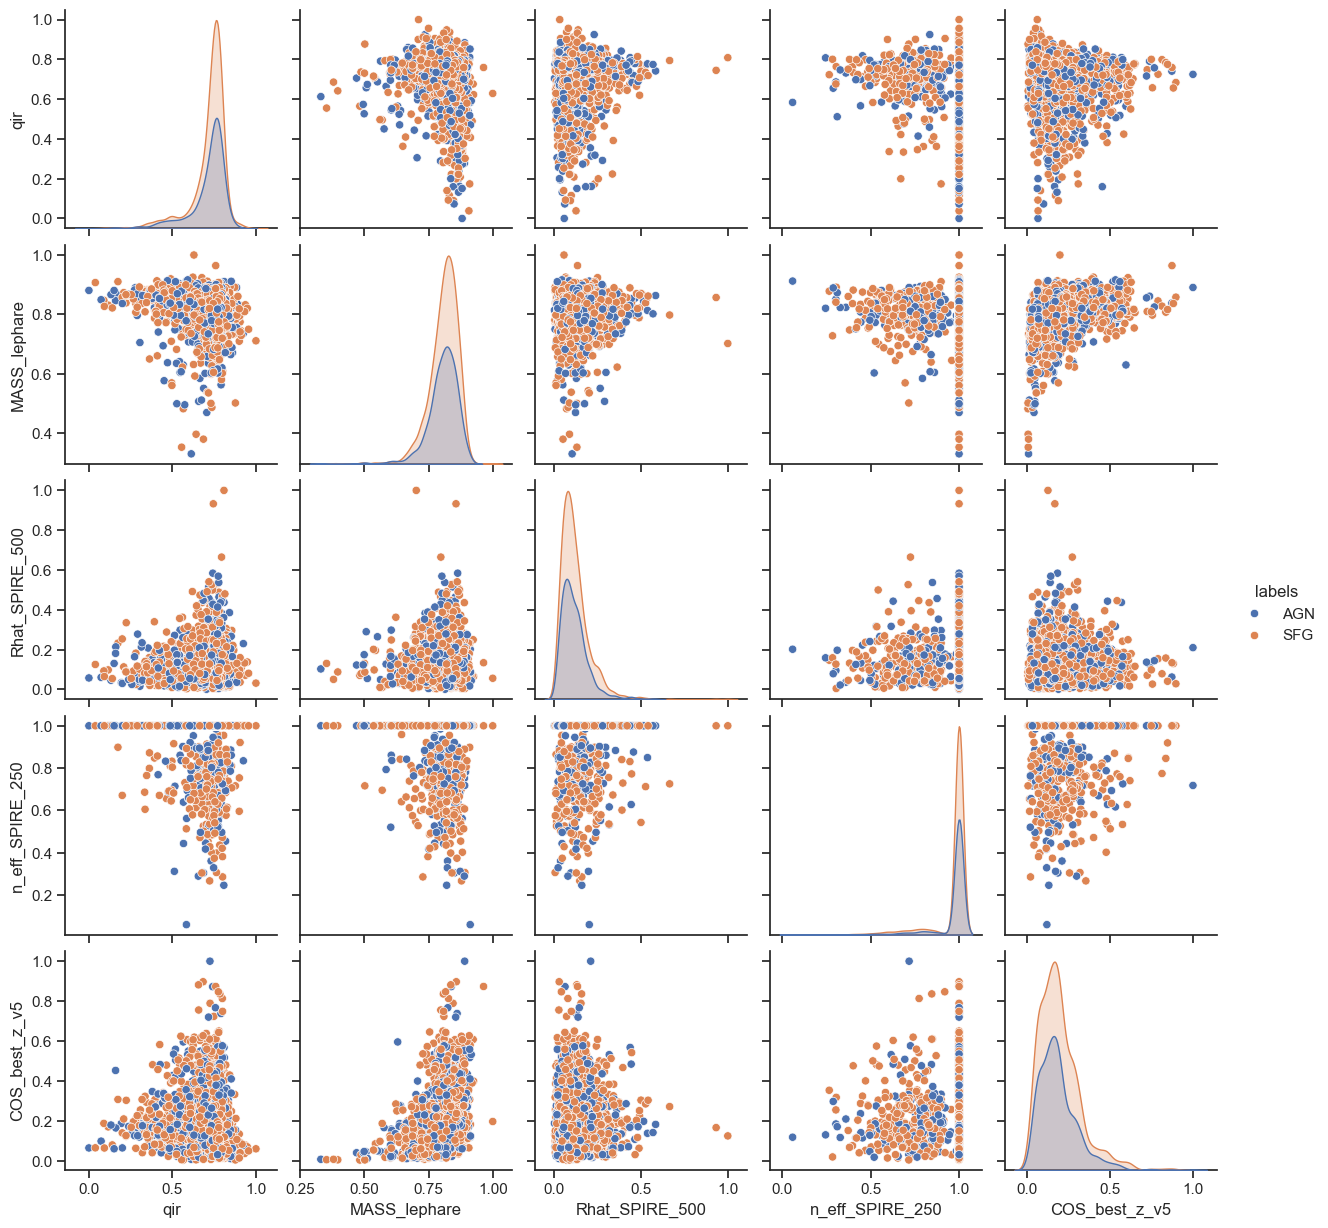

In [195]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Select only the columns you want to plot from your normalized features
columns_to_plot = ["qir", "MASS_lephare", 'Rhat_SPIRE_500', 'n_eff_SPIRE_250', "COS_best_z_v5"]

# 2. Join the features and target cleanly using their matching index
# This discards rows that are not present in BOTH datasets automatically
plot_df = normalized_mightee[columns_to_plot].join(y, how="inner")

# 3. If your target 'y' Series didn't have a column name, pandas name it 'labels' 
# Let's force rename the target column to make sure seaborn can find it
if "labels" not in plot_df.columns:
    # If the series was named something else, rename the last column to 'labels'
    plot_df.rename(columns={plot_df.columns[-1]: "labels"}, inplace=True)

# 4. Generate the pairplot safely
print(f"Plotting pairplot with {len(plot_df)} aligned data points...")
sns.pairplot(plot_df, hue="labels")
plt.show()

----

### Well Done, Now lets Save the data.

In [ ]:
# Before moving on, let's save our processed data as Pandas DataFrames so that we can easily load them in the next notebook for clustering.
import pandas as pd

# Save the normalized feature matrix
normalized_mightee.to_csv("data/normalized_mightee.csv", index=False)

# Save the labels/targets
pd.Series(y, name="target").to_csv("data/y.csv", index=False)